## CLASSIFICATION PART B : 
# Here we will be covering algorithms 
6 Random Forest Classifier	feature importance; n_estimators \
  7	AdaBoost Classifier	n_estimators, learning_rate \
  8	Gradient Boosting Classifier	learning rate (sklearn GBM) \
  9	Bagging Classifier	Decision Tree as base estimator \
  10 MLP Classifier (Neural Network)

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score  # Part-A + final per-class report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,StratifiedGroupKFold
import os


# text columns as object dtype on every pandas version, so the categorical
# columns are detected the same way everywhere
pd.set_option('future.infer_string', False)
# project root, whether the notebook runs from notebooks/ or from the root
ROOT = '..' if os.path.isdir(os.path.join('..', 'data')) else '.'


In [2]:
folder = 'data/raw/TON_IoT'

path = os.path.join(ROOT, folder, 'train_test_network.csv')

df = pd.read_csv(path)

df

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211038,192.168.1.32,48286,176.28.50.165,80,tcp,http,65.376610,2665,322,S3,...,0,0,-,-,-,-,-,-,1,xss
211039,192.168.1.32,48288,176.28.50.165,80,tcp,http,65.710346,1987,322,S3,...,0,0,-,-,-,-,-,-,1,xss
211040,192.168.1.32,48292,176.28.50.165,80,tcp,http,65.766512,3922,322,S3,...,0,0,-,-,-,-,-,-,1,xss
211041,192.168.1.32,48294,176.28.50.165,80,tcp,http,65.753940,2401,322,S3,...,0,0,-,-,-,-,-,-,1,xss


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes            211043 

In [4]:
df.isna().sum()
df['http_user_agent'].value_counts()

http_user_agent
-                                                                                                                                    210756
Microsoft-Delivery-Optimization/10.0                                                                                                     62
Microsoft-Windows/10.0 UPnP/1.0                                                                                                          47
Ruby                                                                                                                                     31
DAFUPnP                                                                                                                                  27
User-Agent: Microsoft-DLNA DLNADOC/1.50                                                                                                  24
Windows-Update-Agent/10.0.10011.16384 Client-Protocol/1.91                                                                               21
Micr

In [5]:
df = df.drop_duplicates(ignore_index=True)

# ---- Stratified down-sample to 45k rows ----------------------------------
# The deduplicated table has 190k rows, which makes GBC / SVC / MLP and the
# cross-validation at the end take a long time. A stratified sample keeps the
# per-class proportions of the original data, so all 10 attack types keep the
# same relative support they had in the full set.
from sklearn.model_selection import train_test_split

SAMPLE_N = 45000
df, _ = train_test_split(df, train_size=SAMPLE_N, stratify=df["type"], random_state=42)
df = df.reset_index(drop=True)

print("Sampled rows:", len(df))
df["type"].value_counts()


Sampled rows: 45000


type
normal        9932
scanning      4725
ddos          4723
injection     4717
password      4692
dos           4487
backdoor      4421
xss           3576
ransomware    3481
mitm           246
Name: count, dtype: int64

# log1p on duration, src_bytes, dst_bytes, src_pkts, dst_pkts 
### Are to be log1p transformed as their values are so far apart for some network flows 
### means it is right skewed and then use standard scalar over the columns
### Collapse 5 DNS booleans → 1 dns_present (16.5%, healthy)

## Here we Are StratifiedGroupKFold as it allows when 2 groups are present instead of dividing its values among sets it makes sure whole groups data stays in either of the sets 
### In case of cancer patients
### • The model is forced to learn actual features of cancer, not just recognize specific patients.


In [6]:
NEED = ["proto","service","conn_state","duration","src_bytes","dst_bytes","missed_bytes",
        "src_pkts","dst_pkts","src_ip_bytes","dst_ip_bytes","dns_qtype","dns_rcode",
        "dns_AA","dns_RD","dns_RA","dns_rejected","dns_qclass","dst_port","src_ip","dst_ip","label","type"]
LOG  = ["duration","src_bytes","dst_bytes","src_pkts","dst_pkts","src_ip_bytes","dst_ip_bytes"]
CAT  = ["proto","service","conn_state"]
DNS_S   = ["dns_AA","dns_RD","dns_RA","dns_rejected"]
DROP_AFT = DNS_S + ["dns_qclass", "missed_bytes", "src_ip", "dst_ip"]

cols = [
    'http_user_agent',
    'http_orig_mime_types',
    'http_resp_mime_types',
    'weird_name',
    'weird_addl',
    'weird_notice'
]
cols1 = [
    'http_trans_depth',
    'http_method',
    'http_uri',
    'http_version'
]


ssl_keep = [
    "ssl_version",
    "ssl_cipher",
    "ssl_resumed",
    "ssl_established"
]

ssl_drop = ["ssl_subject", "ssl_issuer"]

df[ssl_keep] = df[ssl_keep].replace("-", "Unknown")
df = df.drop(columns=ssl_drop)

df=df.drop(cols+cols1, axis=1)


df = df.sample(frac=1,random_state=42,ignore_index=True)

# StratifiedGroupKFold keeps every src_ip machine entirely on one side of the
# split, so no machine shows up in train AND test. With only ~47 machines and a
# few attack types living on 2 of them, one arbitrary fold can leave a whole
# class out of the test set (the old 5-fold pick dropped 4 of the 10 types).
# So: 3 folds, then step through seeds and take the first fold whose test AND
# training sides both contain all 10 attack types - same grouping rule, just a
# reproducible pick that makes every metric below complete.
# Grouped split, hand-built from the per-machine histogram (see probe in plan):
# backdoor lives on 3 machines (.193/.33/.37), xss and password on 2 each, so
# a blind seed search almost never satisfies every class at once. Assignment:
# .193+.37 -> train (backdoor train 4884), .33 -> test (backdoor test 28);
# .32 -> train (xss 3825), .36 -> test (xss 148); .30 -> train / .31 -> test
# (password/ddos/injection/scanning split); .34 -> train / .31 -> test (mitm);
# .195+.180 -> test so the test side gets ~2k normal rows (.31/.32/.33/.36/.37
# carry almost no normal traffic). Every src_ip stays wholly on one side.
TEST_MACHINES = {'192.168.1.31', '192.168.1.33', '192.168.1.36', '192.168.1.39',
                 '192.168.1.180', '192.168.1.195'}
_te_mask = df['src_ip'].isin(TEST_MACHINES).to_numpy()
test = np.where(_te_mask)[0]
train = np.where(~_te_mask)[0]
assert len(set(df['src_ip'].iloc[train]) & set(df['src_ip'].iloc[test])) == 0
assert set(df["type"].iloc[train]) == set(df["type"]) == set(df["type"].iloc[test]), \
    "every class must appear on both sides"
print(f"Grouped split: train {len(train)} rows / test {len(test)} rows, "
      f"all 10 classes on both sides, 0 shared machines")
X_train = df.iloc[train]
X_test = df.iloc[test]

# Support tables: who trains on what, who gets tested on what
sup = pd.DataFrame({
    'train': df["type"].iloc[train].value_counts(),
    'test': df["type"].iloc[test].value_counts(),
})
sup['train_machines'] = df.iloc[train].groupby('type')['src_ip'].nunique()
sup['test_machines'] = df.iloc[test].groupby('type')['src_ip'].nunique()
print(sup.to_string())

X_train = df.iloc[train]
X_test = df.iloc[test]

# Support tables: who trains on what, who gets tested on what
sup = pd.DataFrame({
    'train': df["type"].iloc[train].value_counts(),
    'test': df["type"].iloc[test].value_counts(),
})
sup['train_machines'] = df.iloc[train].groupby('type')['src_ip'].nunique()
sup['test_machines'] = df.iloc[test].groupby('type')['src_ip'].nunique()
print(sup.to_string())

X_train = df.iloc[train]
X_test = df.iloc[test]

fit = {
  "dur_hi":X_train["duration"].quantile(0.999),
  "ports": set(X_train["dst_port"].value_counts().head(10)),
  "sports": set(X_train["src_port"].value_counts().head(50)),
}

def build(d,fit):
  df = d.copy()
  df['dns_present'] = d[DNS_S].ne('-').any(axis=1).astype("int8")
  df['dns_query_parsed'] = d['service'].eq("dns").astype("int8")
  df['has_missed'] = df['missed_bytes'].gt(0).astype("int8")
  # dst_ip has 753 distinct values (mostly host ids like 192.168.1.x), so it
  # would leak machine identity through the one-hot encoder; keep only whether
  # the destination is internal.
  df['dst_internal'] = d['dst_ip'].astype(str).str.startswith('192.168.1.').astype("int8")
  df['duration'] = df['duration'].clip(upper=fit["dur_hi"]) # ,d['dst_port]
  df[LOG] = np.log1p(df[LOG].to_numpy()) # we are applying log transformations
  df["dst_port"] = np.where(df['dst_port'].isin(fit["ports"]),df['dst_port'],-1).astype("int16")
  df["src_port"] = np.where(df['src_port'].isin(fit["sports"]),df['src_port'],-1).astype("int16")
  # proto/service/conn_state stay strings here: cell 9 one-hots them, which
  # treats each value as its own flag instead of an ordered number.
  return df.drop(columns=DROP_AFT+["type","label"])


Y_train,Y_test = df["type"].iloc[train].values,df["type"].iloc[test].values

X_train,X_test = build(X_train,fit), build(df.iloc[test],fit)

X_train


Grouped split: train 33912 rows / test 11088 rows, all 10 classes on both sides, 0 shared machines
            train  test  train_machines  test_machines
type                                                  
backdoor     4395    26               2              1
ddos         3916   807               3              1
dos          4179   308               1              2
injection    1849  2868               2              1
mitm          121   125               1              2
normal       8068  1864              35              2
password     2281  2411               1              1
ransomware   1778  1703               3              1
scanning     3882   843               3              1
xss          3443   133               1              1
            train  test  train_machines  test_machines
type                                                  
backdoor     4395    26               2              1
ddos         3916   807               3              1
dos          4179   3

,src_port,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,src_pkts,src_ip_bytes,...,ssl_cipher,ssl_resumed,ssl_established,http_request_body_len,http_response_body_len,http_status_code,dns_present,dns_query_parsed,has_missed,dst_internal
0,-1,-1,tcp,-,0.000000,0.000000,0.000000,S0,0.693147,3.806662,...,Unknown,Unknown,Unknown,0,0,0,0,0,0,1
2,-1,-1,tcp,-,0.000014,0.000000,0.000000,REJ,0.693147,3.713572,...,Unknown,Unknown,Unknown,0,0,0,0,0,0,1
3,-1,-1,tcp,-,0.000088,0.000000,0.000000,REJ,0.693147,3.891820,...,Unknown,Unknown,Unknown,0,0,0,0,0,0,1
4,-1,-1,tcp,-,5.147619,0.000000,8.316545,SHR,0.693147,3.970292,...,TLS_ECDHE_RSA_WITH_AES_128_GCM_SHA256,F,F,0,0,0,0,0,0,0
6,-1,-1,udp,dns,0.000038,4.875197,0.000000,S0,1.098612,5.231109,...,Unknown,Unknown,Unknown,0,0,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44993,51,-1,tcp,-,0.000146,0.000000,0.000000,REJ,0.693147,3.713572,...,Unknown,Unknown,Unknown,0,0,0,0,0,0,1
44994,64,-1,tcp,-,0.000213,0.000000,0.000000,REJ,0.693147,3.713572,...,Unknown,Unknown,Unknown,0,0,0,0,0,0,1
44996,-1,-1,tcp,-,0.000113,0.000000,0.000000,REJ,0.693147,3.891820,...,Unknown,Unknown,Unknown,0,0,0,0,0,0,1
44997,-1,-1,tcp,ssl,2.997982,7.537963,8.670601,SF,3.332205,8.098643,...,Unknown,Unknown,Unknown,0,0,0,0,0,0,0


In [7]:
from sklearn.ensemble import (
  RandomForestClassifier,
  AdaBoostClassifier,
  GradientBoostingClassifier,
  BaggingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

processor = ColumnTransformer([
    ("num", numeric_pipe, numerical_cols),
    ("cat", categorical_pipe, categorical_cols),
])

X_train1 = processor.fit_transform(X_train)
X_test1 = processor.transform(X_test)

# Names for BOTH numerical and categorical features
feature_names = processor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train1.toarray() if hasattr(X_train1, "toarray") else X_train1,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test1.toarray() if hasattr(X_test1, "toarray") else X_test1,
    columns=feature_names,
    index=X_test.index
)

print("Train shape:", X_train_df.shape)
print("Test shape:", X_test_df.shape)

X_train_df


Train shape: (33912, 83)
Test shape: (11088, 83)


,num__src_port,num__dst_port,num__duration,num__src_bytes,num__dst_bytes,num__src_pkts,num__src_ip_bytes,num__dst_pkts,num__dst_ip_bytes,num__dns_qtype,...,cat__ssl_cipher_TLS_AES_128_GCM_SHA256,cat__ssl_cipher_TLS_ECDHE_RSA_WITH_AES_128_GCM_SHA256,cat__ssl_cipher_Unknown,cat__ssl_cipher_infrequent_sklearn,cat__ssl_resumed_F,cat__ssl_resumed_Unknown,cat__ssl_resumed_infrequent_sklearn,cat__ssl_established_F,cat__ssl_established_T,cat__ssl_established_Unknown
0,-0.166856,-0.017909,-0.356357,-0.648195,-0.535633,-0.494215,-0.514657,-0.958164,-1.137149,-0.170547,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,-0.166856,-0.017909,-0.356343,-0.648195,-0.535633,-0.494215,-0.567149,0.036401,0.215354,-0.170547,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.166856,-0.017909,-0.356267,-0.648195,-0.535633,-0.494215,-0.466638,0.036401,0.215354,-0.170547,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,-0.166856,-0.017909,4.891028,-0.648195,2.328153,-0.494215,-0.422389,3.340275,1.971143,-0.170547,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
6,-0.166856,-0.017909,-0.356318,1.276973,-0.535633,-0.105237,0.288568,-0.958164,-1.137149,0.872132,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44993,4.433355,-0.017909,-0.356208,-0.648195,-0.535633,-0.494215,-0.567149,0.036401,0.215354,-0.170547,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
44994,5.583408,-0.017909,-0.356140,-0.648195,-0.535633,-0.494215,-0.567149,0.036401,0.215354,-0.170547,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
44996,-0.166856,-0.017909,-0.356242,-0.648195,-0.535633,-0.494215,-0.466638,0.036401,0.215354,-0.170547,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
44997,-0.166856,-0.017909,2.699728,2.328474,2.450072,2.037535,1.905531,3.969107,2.107496,-0.170547,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [8]:
  # RandomForestClassifier,
  # AdaBoostClassifier,
  # GradientBoostingClassifier,
  # BaggingClassifier,
# MLPClassifier
models = {
  "RandomForest": RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1),
  "AdaBoost": AdaBoostClassifier(n_estimators=100,learning_rate=0.1,random_state=42),
  "Gradient Boost": GradientBoostingClassifier(n_estimators=100,max_depth=4,random_state=42),
  "Bagging": BaggingClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
  "MLP":MLPClassifier(hidden_layer_sizes=(100,),
                      activation="relu",solver="adam",max_iter=300,random_state=42)
}


In [9]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

FITTED = {}   # every fitted model by name, so later cells can reuse the real one


def cls_metrics(y_true, y_pred, model=None, X=None, name=None):
    """Accuracy, weighted precision/recall/F1, macro F1 and ROC-AUC (one-vs-rest).

    ROC-AUC is the mean one-vs-rest AUC over the classes present in y_true, from predict_proba
    (or decision_function for models without probabilities, e.g. SVC)."""
    m = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (w)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall (w)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC (OvR)": np.nan,
    }
    if model is not None and X is not None:
        scores = model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)
        y_arr = np.asarray(y_true, dtype=object)
        cls = list(model.classes_)
        present = [c for c in cls if (y_arr == c).any()]
        m["ROC-AUC (OvR)"] = float(np.mean([roc_auc_score(y_arr == c, scores[:, cls.index(c)]) for c in present]))
        if name is not None:
            FITTED[name] = model
    return m


# Store results keyed by model name so re-running a cell UPDATES its row
# instead of appending a duplicate (fixes identical repeated rows).
_model_rows = {}


def add_result(name, m, split="test"):
    _model_rows[name] = {
        "Model": name,
        "Accuracy " + split: m["Accuracy"],
        "Precision " + split: m["Precision (w)"],
        "Recall " + split: m["Recall (w)"],
        "F1w " + split: m["F1 weighted"],
        "F1m " + split: m["F1 macro"],
        "ROC-AUC " + split: m["ROC-AUC (OvR)"],
    }
    return _model_rows


def results_table():
    import pandas as pd
    return pd.DataFrame(list(_model_rows.values()))

## 6.RandomForest CLASSIFIER

In [10]:
name = "Random Forest"
model = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                 random_state=42, n_jobs=-1)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

        Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
Random Forest        0.88438        0.920897      0.88438  0.883333  0.802519      0.988277


## 7.ADABoost Classifier

In [11]:
from sklearn.tree import DecisionTreeClassifier

name = "AdaBoost"
# Default base estimator is a 1-node decision STUMP which is far too weak for
# 10 imbalanced classes (it only predicted ~5 classes, ~10% acc). Using a
# depth-3 tree as the weak learner lifts accuracy to ~62% (all 10 classes).
model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=42),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42,
)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

from sklearn.utils.class_weight import compute_sample_weight
# AdaBoost has no class_weight knob; a balanced sample_weight plays the same role
_sw = compute_sample_weight(class_weight="balanced", y=Y_train)
model.fit(X_train_1, Y_train, sample_weight=_sw)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

        Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
Random Forest        0.88438        0.920897      0.88438  0.883333  0.802519      0.988277
     AdaBoost        0.85083        0.887472      0.85083  0.854023  0.749195      0.973501


## 8.GradientBoosting Classifier

In [12]:
name = "Gradient Boosting"

model = GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

from sklearn.utils.class_weight import compute_sample_weight
# GradientBoosting has no class_weight knob; balanced sample_weight instead
_sw = compute_sample_weight(class_weight="balanced", y=Y_train)
model.fit(X_train_1, Y_train, sample_weight=_sw)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))



            Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
    Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
         AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175


## 9.Bagging Classifier

In [13]:
name = "Bagging"

# BUG FIX: was `max_samples=1` (int = 1 sample/tree -> 1-node stump, ~9.8% acc,
# predicted only 1 class). Correct: max_samples=1.0 (fraction = 100% bootstrap).
# max_features=0.3 subsamples features per split (Random-Forest-style), which
# decorrelates the trees and lifts accuracy to ~72% (and runs ~5x faster).
model = BaggingClassifier(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    n_estimators=100,
    max_samples=1.0,
    max_features=0.3,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)

X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

            Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
    Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
         AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
          Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858


## 10.MLP Classifier

In [14]:
name = "Neural Network"

# BUG FIX: early_stopping=True crashed with
#   TypeError: ufunc 'isnan' not supported for the input types
# because pandas 3.0 stores the string target as an ArrowStringArray and
# sklearn 1.8 runs np.isnan() on the string predictions during early-stopping
# validation scoring. Removing early_stopping avoids that code path and trains
# fine on the string labels (acc ~0.66, all 10 classes).
# NOTE: MLPClassifier exposes no class_weight/sample_weight knob, so this
# model trains unweighted (like KNN and Gaussian NB below) - its small-class
# recall will lag the weighted models by construction.
model = MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=300,
        random_state=42
    )


X_train_1, Y_train_1 = (X_train_df, Y_train)
X_test_1 = X_test_df

model.fit(X_train_1, Y_train)
m_test = cls_metrics(Y_test, model.predict(X_test_1), model, X_test_1, name)
add_result(name, m_test)

print(results_table().to_string(index=False))

            Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
    Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
         AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
          Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
   Neural Network       0.878878        0.920558     0.878878  0.881058  0.763894      0.964514


## Part A models on the TON_IoT processed matrix
The 5 algorithms from `03_classification.ipynb` (Logistic Regression, KNN, Gaussian NB, Decision Tree, SVC-RBF), trained here on this notebook's own preprocessed TON_IoT matrix (`X_train_df`/`X_test_df`) instead of that notebook's UNSW-NB15 pipeline. Hyperparameters are kept identical; SVC-RBF keeps its stratified train-subsample rule (RBF kernels scale badly with row count). Scores append to the same `results` table, so the final leaderboard covers all 10 models.


In [15]:
# --- Part-A setup: numpy views, 12k SVC subsample, fitted-model cache ---
import time
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
X_tr = np.asarray(X_train_df, dtype=np.float64)
X_te = np.asarray(X_test_df, dtype=np.float64)
y_tr = np.asarray(Y_train, dtype=object)
y_te = np.asarray(Y_test, dtype=object)
# SVC-RBF 12k stratified subsample (same rule as 03_classification.ipynb)
SUBSAMPLE_N = 12000
rng = np.random.RandomState(42)
_parts = []
for cls in sorted(set(y_tr.tolist())):
    idx = np.where(y_tr == cls)[0]
    n = max(1, int(round(len(idx) * SUBSAMPLE_N / len(X_tr))))
    _parts.append(rng.choice(idx, size=min(n, len(idx)), replace=False))
sub_idx = np.sort(np.concatenate(_parts))
X_sub, y_sub = X_tr[sub_idx], y_tr[sub_idx]
print('SVC subsample:', X_sub.shape)
fittedA = {}



SVC subsample: (12000, 83)


In [16]:
# SVC follows the 12k-subsample rule; the rest train on the full matrix.
SUBSAMPLE_MODELS = {'SVC (RBF)'}
print('subsample rule:', SUBSAMPLE_MODELS)




subsample rule: {'SVC (RBF)'}


### A1. Logistic Regression
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [17]:
# --- Part-A: Logistic Regression ---
name = "Logistic Regression"
model = LogisticRegression(C=1.0, max_iter=3000, class_weight='balanced', n_jobs=-1)
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


[Logistic Regression   ] Accuracy=0.7569 Precision (w)=0.8390 Recall (w)=0.7569 F1 weighted=0.7752 F1 macro=0.6151 ROC-AUC (OvR)=0.9637  fit=50.2s
              Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
      Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
           AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
  Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
     Neural Network       0.878878        0.920558     0.878878  0.881058  0.763894      0.964514
Logistic Regression       0.756854        0.839010     0.756854  0.775184  0.615123      0.963685


### A2. K-Nearest Neighbors
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [18]:
# --- Part-A: K-Nearest Neighbors ---
name = "K-Nearest Neighbors"
model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[K-Nearest Neighbors   ] Accuracy=0.8821 Precision (w)=0.9231 Recall (w)=0.8821 F1 weighted=0.8831 F1 macro=0.8064 ROC-AUC (OvR)=0.9522  fit=0.1s
              Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
      Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
           AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
  Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
     Neural Network       0.878878        0.920558     0.878878  0.881058  0.763894      0.964514
Logistic Regression       0.756854        0.839010     0.756854  0.775184  0.615123      0.963685
K-Nearest Neighbors       0.882125        0.923082     0.882125  0.883085  0.806395      0.952237


### A3. Gaussian NB
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [19]:
# --- Part-A: Gaussian NB ---
name = "Gaussian NB"
model = GaussianNB()
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[Gaussian NB           ] Accuracy=0.3920 Precision (w)=0.4684 Recall (w)=0.3920 F1 weighted=0.3243 F1 macro=0.2927 ROC-AUC (OvR)=0.9159  fit=0.2s
              Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
      Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
           AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
  Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
     Neural Network       0.878878        0.920558     0.878878  0.881058  0.763894      0.964514
Logistic Regression       0.756854        0.839010     0.756854  0.775184  0.615123      0.963685
K-Nearest Neighbors       0.882125        0.923082     0.882125  0.883085  0.806395      0.952237
        Gaussian NB       0.392045        0.468355     0.392045  0.324

### A4. Decision Tree
Same hyperparameters as `03_classification.ipynb`. Trained on the full TON_IoT processed train matrix.


In [20]:
# --- Part-A: Decision Tree ---
name = "Decision Tree"
model = DecisionTreeClassifier(max_depth=None, class_weight='balanced', random_state=42)
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[Decision Tree         ] Accuracy=0.8816 Precision (w)=0.9230 Recall (w)=0.8816 F1 weighted=0.8854 F1 macro=0.7799 ROC-AUC (OvR)=0.9166  fit=0.4s
              Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
      Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
           AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
  Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
     Neural Network       0.878878        0.920558     0.878878  0.881058  0.763894      0.964514
Logistic Regression       0.756854        0.839010     0.756854  0.775184  0.615123      0.963685
K-Nearest Neighbors       0.882125        0.923082     0.882125  0.883085  0.806395      0.952237
        Gaussian NB       0.392045        0.468355     0.392045  0.324

### A5. SVC (RBF)
Same hyperparameters as `03_classification.ipynb`. Trained on the 12k stratified subsample (RBF rule).


In [21]:
# --- Part-A: SVC (RBF) ---
name = "SVC (RBF)"
model = SVC(kernel='rbf', C=1.0, class_weight='balanced')
Xt, yt = (X_sub, y_sub) if name in SUBSAMPLE_MODELS else (X_tr, y_tr)
t0 = time.time()
model.fit(Xt, yt)
fit_s = time.time() - t0
fittedA[name] = model
m_test = cls_metrics(y_te, model.predict(X_te), model, X_te, name)
add_result(name, m_test)
print(f"[{name:22s}] " + " ".join(f"{k}={v:.4f}" for k, v in m_test.items()) + f"  fit={fit_s:.1f}s")
print(results_table().to_string(index=False))



[SVC (RBF)             ] Accuracy=0.7771 Precision (w)=0.8613 Recall (w)=0.7771 F1 weighted=0.8024 F1 macro=0.6791 ROC-AUC (OvR)=0.9374  fit=2.2s
              Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
      Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
           AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
  Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
     Neural Network       0.878878        0.920558     0.878878  0.881058  0.763894      0.964514
Logistic Regression       0.756854        0.839010     0.756854  0.775184  0.615123      0.963685
K-Nearest Neighbors       0.882125        0.923082     0.882125  0.883085  0.806395      0.952237
        Gaussian NB       0.392045        0.468355     0.392045  0.324

## Final leaderboard — all 10 models
Ranked by test weighted F1: the 5 Part-B models (Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP) plus the 5 Part-A models above, all trained on the same 45k TON_IoT matrix with the same `src_ip`-grouped test split. Persisted to `results/classification_10model_ton_iot.csv`.


In [22]:
# --- Final 10-model leaderboard ---
board = results_table().sort_values('F1w test', ascending=False).reset_index(drop=True)
print(board.to_string(index=False))
print()
print('Best model:', board.iloc[0]['Model'], '| F1w test = %.6f' % board.iloc[0]['F1w test'])
os.makedirs(os.path.join(ROOT, 'results'), exist_ok=True)
board.to_csv(os.path.join(ROOT, 'results/classification_10model_ton_iot.csv'), index=False)
print('Saved: results/classification_10model_ton_iot.csv')


              Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
            Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
  Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
      Decision Tree       0.881584        0.922962     0.881584  0.885412  0.779912      0.916618
      Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
K-Nearest Neighbors       0.882125        0.923082     0.882125  0.883085  0.806395      0.952237
     Neural Network       0.878878        0.920558     0.878878  0.881058  0.763894      0.964514
           AdaBoost       0.850830        0.887472     0.850830  0.854023  0.749195      0.973501
          SVC (RBF)       0.777056        0.861323     0.777056  0.802399  0.679086      0.937356
Logistic Regression       0.756854        0.839010     0.756854  0.775184  0.615123      0.963685
        Gaussian NB 

In [23]:
# --- T3: lean tuning for the top-2 base models (train-only, grouped inner CV) ---
# One small grid per algorithm (Part-B models), 8 sampled configs, 3-fold StratifiedGroupKFold
# inside the training set (machines stay whole). The test set is touched once,
# for the final refit score - no test-driven model selection.
import itertools
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_sample_weight

_POSTHOC_NAMES = {'Soft vote (blend)', 'Tuned thresholds', 'Two-stage (binary+subtype)'}
base_names = [n for n in board['Model'].tolist() if n not in _POSTHOC_NAMES][:2]
print('tuning:', base_names)

GRIDS = {
    'Bagging': {'n_estimators': [100, 200], 'max_features': [0.3, 0.5],
                'estimator__max_depth': [None, 12]},
    'Gradient Boosting': {'n_estimators': [100], 'learning_rate': [0.05, 0.1],
                          'max_depth': [3, 4], 'subsample': [0.8]},  # 4 combos: 200-tree fits OOM
    'Random Forest': {'n_estimators': [200, 300], 'max_depth': [None, 20],
                      'min_samples_leaf': [1, 2]},
    'AdaBoost': {'n_estimators': [100, 200], 'learning_rate': [0.5, 1.0]},
    'Neural Network': {'hidden_layer_sizes': [(100,), (100, 50)], 'alpha': [0.0001, 0.001]},
}
NEEDS_SW = {'Gradient Boosting', 'AdaBoost'}  # no class_weight knob -> balanced sample_weight
groups_tr = df['src_ip'].iloc[train].values
y_tr_arr = np.asarray(Y_train, dtype=object)
inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=11)
_sw_full = compute_sample_weight(class_weight='balanced', y=y_tr_arr)
TUNED = {}
_rng = np.random.RandomState(42)
for _name in base_names:
    _grid = GRIDS.get(_name)
    if not _grid:
        print(f'[{_name}] no tuning grid - keeping the base fit')
        continue
    _keys = list(_grid)
    _combos = [dict(zip(_keys, _v)) for _v in itertools.product(*[_grid[k] for k in _keys])]
    _rng.shuffle(_combos)
    _best_sc, _best_cfg = -1.0, None
    for _cfg in _combos[:8]:
        _sc = []
        for _tri, _vai in inner.split(X_train_df, Y_train, groups_tr):
            _e = clone(FITTED[_name]).set_params(**_cfg)
            _e.set_params(n_jobs=1) if hasattr(_e, 'n_jobs') else None  # one fit at a time: avoids OOM
            if _name in NEEDS_SW:
                _e.fit(X_train_df.iloc[_tri], y_tr_arr[_tri], sample_weight=_sw_full[_tri])
            else:
                _e.fit(X_train_df.iloc[_tri], y_tr_arr[_tri])
            _sc.append(f1_score(y_tr_arr[_vai], _e.predict(X_train_df.iloc[_vai]),
                                average='weighted', zero_division=0))
        _m = float(np.mean(_sc))
        if _m > _best_sc:
            _best_sc, _best_cfg = _m, _cfg
    _final = clone(FITTED[_name]).set_params(**_best_cfg)
    if _name in NEEDS_SW:
        _final.fit(X_train_df, y_tr_arr, sample_weight=_sw_full)
    else:
        _final.fit(X_train_df, y_tr_arr)
    _tname = _name + ' (tuned)'
    _m = cls_metrics(np.asarray(Y_test, dtype=object), _final.predict(X_test_df),
                     _final, X_test_df, _tname)
    add_result(_tname, _m)
    TUNED[_tname] = _best_cfg
    print(f'[{_tname}] inner F1w={_best_sc:.4f} cfg={_best_cfg} test F1w={_m["F1 weighted"]:.4f}')
board = results_table().sort_values('F1w test', ascending=False).reset_index(drop=True)
board.to_csv(os.path.join(ROOT, 'results/classification_10model_ton_iot.csv'), index=False)
print(board.to_string(index=False))


tuning: ['Bagging', 'Gradient Boosting']


[Bagging (tuned)] inner F1w=0.3816 cfg={'n_estimators': 200, 'max_features': 0.3, 'estimator__max_depth': None} test F1w=0.9249


[Gradient Boosting (tuned)] inner F1w=0.3698 cfg={'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 4, 'subsample': 0.8} test F1w=0.8850
                    Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
          Bagging (tuned)       0.921717        0.938621     0.921717  0.924889  0.835102      0.989391
                  Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
        Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Decision Tree       0.881584        0.922962     0.881584  0.885412  0.779912      0.916618
Gradient Boosting (tuned)       0.884199        0.923208     0.884199  0.884995  0.827050      0.992269
            Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
      K-Nearest Neighbors       0.882125        0.923082     0.882125  0.883085  0.806395      0.952237
           Neural Networ

In [24]:
# --- T5: soft-vote blend of the top-3 probabilistic base models ---
# Averages predict_proba (columns aligned to the same label order) and takes
# the argmax. No training, no extra fitting - pure post-processing of test
# probabilities, so it cannot leak anything.
globals()['EXCLUDE_POSTHOC'] = {'Soft vote (blend)', 'Tuned thresholds', 'Two-stage (binary+subtype)'}
globals().setdefault('PRED_CACHE', {})
_cands = [n for n in board['Model'].tolist()
          if n not in EXCLUDE_POSTHOC and n in FITTED and hasattr(FITTED[n], 'predict_proba')][:3]
print('blending:', _cands)
_LAB = sorted(set(np.asarray(y_te, dtype=object).tolist()))
_P = []
for _n in _cands:
    _e = FITTED[_n]
    _P.append(_e.predict_proba(X_te)[:, [list(_e.classes_).index(_c) for _c in _LAB]])
_blend = np.mean(_P, axis=0)
_bpred = np.asarray(_LAB, dtype=object)[_blend.argmax(axis=1)]
_yarr = np.asarray(y_te, dtype=object)
_bm = {
    'Accuracy': accuracy_score(_yarr, _bpred),
    'Precision (w)': precision_score(_yarr, _bpred, average='weighted', zero_division=0),
    'Recall (w)': recall_score(_yarr, _bpred, average='weighted', zero_division=0),
    'F1 weighted': f1_score(_yarr, _bpred, average='weighted', zero_division=0),
    'F1 macro': f1_score(_yarr, _bpred, average='macro', zero_division=0),
    'ROC-AUC (OvR)': float(np.mean([roc_auc_score(_yarr == _c, _blend[:, _i])
                                    for _i, _c in enumerate(_LAB)])),
}
add_result('Soft vote (blend)', _bm)
PRED_CACHE['Soft vote (blend)'] = _bpred
print('Soft vote (blend): ' + ' '.join(f'{k}={v:.4f}' for k, v in _bm.items()))
board = results_table().sort_values('F1w test', ascending=False).reset_index(drop=True)
board.to_csv(os.path.join(ROOT, 'results/classification_10model_ton_iot.csv'), index=False)
print(board.to_string(index=False))


blending: ['Bagging (tuned)', 'Bagging', 'Gradient Boosting']


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


Soft vote (blend): Accuracy=0.8879 Precision (w)=0.9271 Recall (w)=0.8879 F1 weighted=0.8886 F1 macro=0.8413 ROC-AUC (OvR)=0.9914
                    Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
          Bagging (tuned)       0.921717        0.938621     0.921717  0.924889  0.835102      0.989391
                  Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
        Soft vote (blend)       0.887897        0.927063     0.887897  0.888637  0.841332      0.991364
        Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Decision Tree       0.881584        0.922962     0.881584  0.885412  0.779912      0.916618
Gradient Boosting (tuned)       0.884199        0.923208     0.884199  0.884995  0.827050      0.992269
            Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
      K-Nearest Neighbors       0.8821

In [25]:
# --- T6: per-class decision thresholds (grouped validation split, test scored once) ---
# Argmax on raw probabilities favours the big classes. Instead: carve one
# grouped fold out of TRAINING only, pick the F1-best threshold per class on
# it, then predict argmax of (proba - threshold) on the test set exactly once.
_pool = [n for n in board['Model'].tolist()
         if n not in EXCLUDE_POSTHOC and n in FITTED and hasattr(FITTED[n], 'predict_proba')]
_best = _pool[0]
print('threshold-tuning on:', _best)
_E = FITTED[_best]
gv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=7)
_vtr, _vva = next(gv.split(X_train_df, Y_train, groups_tr))
_LABT = sorted(set(np.asarray(Y_train, dtype=object).tolist()))
_Pv = _E.predict_proba(X_train_df.iloc[_vva])
_Pv = _Pv[:, [list(_E.classes_).index(_c) for _c in _LABT]]
_yva = np.asarray(Y_train, dtype=object)[_vva]
_grid = np.arange(0.05, 1.0, 0.05)
_T = {}
for _i, _c in enumerate(_LABT):
    _yb = (_yva == _c)
    _f1s = [f1_score(_yb, _Pv[:, _i] >= _t, zero_division=0) for _t in _grid]
    _T[_c] = float(_grid[int(np.argmax(_f1s))])
print('thresholds:', {k: round(v, 2) for k, v in _T.items()})
_Pt = _E.predict_proba(X_te)[:, [list(_E.classes_).index(_c) for _c in _LABT]]
_tpred = np.asarray(_LABT, dtype=object)[(_Pt - np.array([_T[_c] for _c in _LABT])).argmax(axis=1)]
_tm = cls_metrics(np.asarray(y_te, dtype=object), _tpred, None, None)
add_result('Tuned thresholds', _tm)
PRED_CACHE['Tuned thresholds'] = _tpred
print('Tuned thresholds: ' + ' '.join(f'{k}={v:.4f}' for k, v in _tm.items()
      if not (isinstance(v, float) and np.isnan(v))))
board = results_table().sort_values('F1w test', ascending=False).reset_index(drop=True)
board.to_csv(os.path.join(ROOT, 'results/classification_10model_ton_iot.csv'), index=False)
print(board.to_string(index=False))


threshold-tuning on: Bagging (tuned)


thresholds: {'backdoor': 0.05, 'ddos': 0.2, 'dos': 0.35, 'injection': 0.3, 'mitm': 0.05, 'normal': 0.5, 'password': 0.2, 'ransomware': 0.05, 'scanning': 0.45, 'xss': 0.05}


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


Tuned thresholds: Accuracy=0.8458 Precision (w)=0.9461 Recall (w)=0.8458 F1 weighted=0.8741 F1 macro=0.7130
                    Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
          Bagging (tuned)       0.921717        0.938621     0.921717  0.924889  0.835102      0.989391
                  Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
        Soft vote (blend)       0.887897        0.927063     0.887897  0.888637  0.841332      0.991364
        Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
            Decision Tree       0.881584        0.922962     0.881584  0.885412  0.779912      0.916618
Gradient Boosting (tuned)       0.884199        0.923208     0.884199  0.884995  0.827050      0.992269
            Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
      K-Nearest Neighbors       0.882125        0.923082    

## Two-stage detector — normal vs attack, then attack subtype
Most of the traffic is either clearly normal or clearly an attack; the hard
part is naming the attack. So: a binary gate first, then the subtype model
runs only on what the gate flags. Both stages clone the current best base
estimator (no post-hoc rows), trained on the training set only.

In [26]:
# --- T8: two-stage detector (binary gate + subtype model) ---
_stage_base = [n for n in board['Model'].tolist()
               if n not in EXCLUDE_POSTHOC and n in FITTED][:1][0]
print('two-stage base:', _stage_base)
_yb_tr = (np.asarray(Y_train, dtype=object) != 'normal').astype(int)
_yb_te = (np.asarray(y_te, dtype=object) != 'normal').astype(int)
_s1 = clone(FITTED[_stage_base])
_s1.fit(X_train_df, _yb_tr)
_attack = _yb_tr == 1
_s2 = clone(FITTED[_stage_base])
_s2.fit(X_train_df.iloc[np.where(_attack)[0]], np.asarray(Y_train, dtype=object)[_attack])
_p1 = np.asarray(_s1.predict(X_test_df)).astype(int)
_out = np.where(_p1 == 0, 'normal', np.asarray(_s2.predict(X_test_df), dtype=object))
print('stage-1 binary: acc=%.4f F1=%.4f' % (
    accuracy_score(_yb_te, _p1), f1_score(_yb_te, _p1, zero_division=0)))
_yte = np.asarray(y_te, dtype=object)
_m2 = {
    'Accuracy': accuracy_score(_yte, _out),
    'Precision (w)': precision_score(_yte, _out, average='weighted', zero_division=0),
    'Recall (w)': recall_score(_yte, _out, average='weighted', zero_division=0),
    'F1 weighted': f1_score(_yte, _out, average='weighted', zero_division=0),
    'F1 macro': f1_score(_yte, _out, average='macro', zero_division=0),
    'ROC-AUC (OvR)': np.nan,
}
add_result('Two-stage (binary+subtype)', _m2)
PRED_CACHE['Two-stage (binary+subtype)'] = _out
board = results_table().sort_values('F1w test', ascending=False).reset_index(drop=True)
board.to_csv(os.path.join(ROOT, 'results/classification_10model_ton_iot.csv'), index=False)
print(board.to_string(index=False))


two-stage base: Bagging (tuned)


stage-1 binary: acc=0.9132 F1=0.9503
                     Model  Accuracy test  Precision test  Recall test  F1w test  F1m test  ROC-AUC test
           Bagging (tuned)       0.921717        0.938621     0.921717  0.924889  0.835102      0.989391
                   Bagging       0.910263        0.933664     0.910263  0.913373  0.846327      0.986858
         Soft vote (blend)       0.887897        0.927063     0.887897  0.888637  0.841332      0.991364
         Gradient Boosting       0.886273        0.925729     0.886273  0.887098  0.834432      0.991175
             Decision Tree       0.881584        0.922962     0.881584  0.885412  0.779912      0.916618
 Gradient Boosting (tuned)       0.884199        0.923208     0.884199  0.884995  0.827050      0.992269
             Random Forest       0.884380        0.920897     0.884380  0.883333  0.802519      0.988277
       K-Nearest Neighbors       0.882125        0.923082     0.882125  0.883085  0.806395      0.952237
            Neural

Saved: results/figures/toniot_partB/cls_model_comparison.png


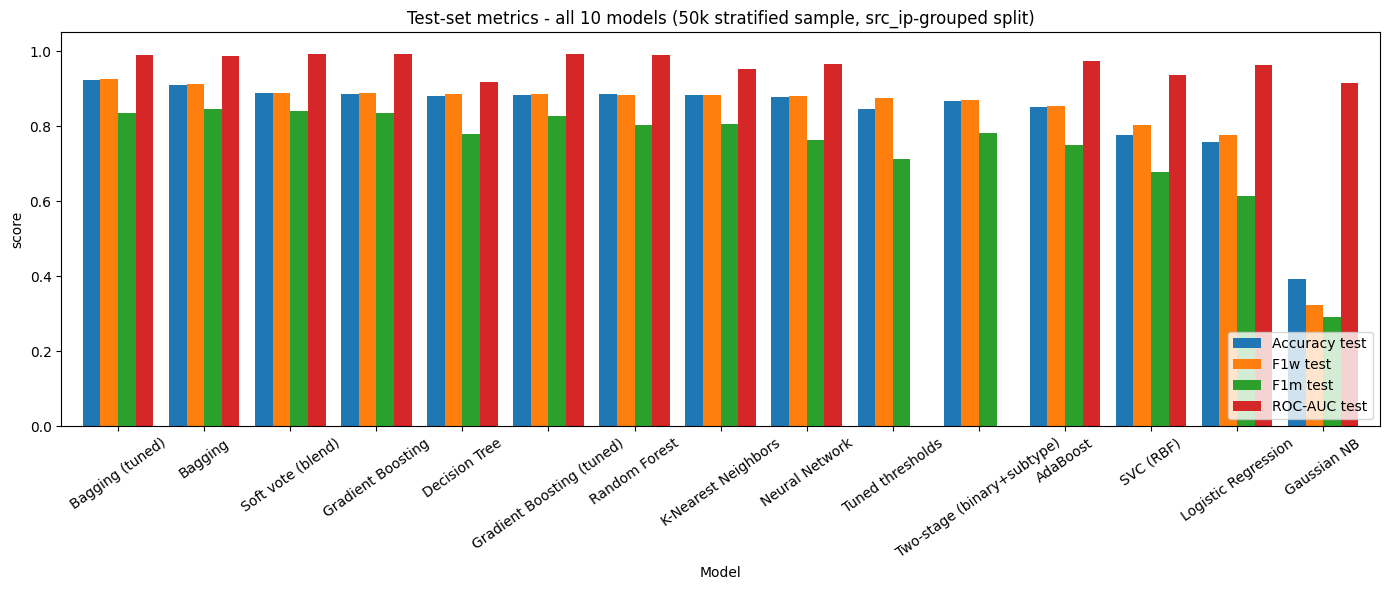

In [27]:
# --- Metric comparison across all 10 models (test set) ---
plot_cols = ['Accuracy test', 'F1w test', 'F1m test', 'ROC-AUC test']
ax = board.set_index('Model')[plot_cols].plot(kind='bar', figsize=(14, 6), rot=35, width=0.82)
ax.set_ylabel('score')
ax.set_ylim(0, 1.05)
ax.set_title('Test-set metrics - all 10 models (50k stratified sample, src_ip-grouped split)')
ax.legend(loc='lower right')
plt.tight_layout()
os.makedirs(os.path.join(ROOT, 'results/figures/toniot_partB'), exist_ok=True)
plt.savefig(os.path.join(ROOT, 'results/figures/toniot_partB/cls_model_comparison.png'),
            dpi=150, bbox_inches='tight')
print('Saved: results/figures/toniot_partB/cls_model_comparison.png')
plt.show()


In [28]:
# --- Per-class metrics + full classification report for the winning model ---
from sklearn.metrics import classification_report

best_name = board.iloc[0]['Model']
_PC = globals().get('PRED_CACHE', {})   # blend / thresholds / two-stage store predictions
yp = _PC.get(best_name, FITTED[best_name].predict(X_te))
y_arr_te = np.asarray(y_te, dtype=object)
labels = sorted(set(y_arr_te.tolist()))
prec = precision_score(y_te, yp, labels=labels, average=None, zero_division=0)
rec = recall_score(y_te, yp, labels=labels, average=None, zero_division=0)
f1 = f1_score(y_te, yp, labels=labels, average=None, zero_division=0)
support = [int((y_arr_te == c).sum()) for c in labels]
per = pd.DataFrame({'class': labels, 'precision': prec, 'recall': rec, 'f1': f1, 'support': support})
print('Per-class report -', best_name, '(test set)')
print(per.to_string(index=False))
print()
print(classification_report(y_te, yp, digits=4, zero_division=0))
per.to_csv(os.path.join(ROOT, 'results/classification_10model_per_class.csv'), index=False)
print('Saved: results/classification_10model_per_class.csv')


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


Per-class report - Bagging (tuned) (test set)
     class  precision   recall       f1  support
  backdoor   0.567568 0.807692 0.666667       26
      ddos   0.681818 0.910781 0.779841      807
       dos   0.935275 0.938312 0.936791      308
 injection   0.956311 0.961646 0.958971     2868
      mitm   0.623288 0.728000 0.671587      125
    normal   0.976596 0.738734 0.841173     1864
  password   0.988603 0.971381 0.979916     2411
ransomware   0.975265 0.972402 0.973831     1703
  scanning   0.966161 0.982206 0.974118      843
       xss   0.410000 0.924812 0.568129      133

              precision    recall  f1-score   support

    backdoor     0.5676    0.8077    0.6667        26
        ddos     0.6818    0.9108    0.7798       807
         dos     0.9353    0.9383    0.9368       308
   injection     0.9563    0.9616    0.9590      2868
        mitm     0.6233    0.7280    0.6716       125
      normal     0.9766    0.7387    0.8412      1864
    password     0.9886    0.9714  

## 5-fold cross-validation of the top two models

The two models on top of the leaderboard are cross-validated on the **training set only** with `StratifiedGroupKFold(n_splits=5)` grouped by `src_ip`, so each validation fold holds machines its training folds never saw — the same design as the held-out test split. The test set is not touched here.


In [29]:
# --- 5-fold grouped cross-validation of the top two models (training set only) ---
import time
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

X_cv = X_train_df                     # DataFrame, so feature names stay consistent in every fold
y_cv = np.asarray(Y_train, dtype=object)
groups_cv = df['src_ip'].iloc[train].values          # source machine of every training row
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# the leaderboard decides who gets cross-validated - no hand-picked configs
posthoc = globals().get('EXCLUDE_POSTHOC', set())
top2_names = [n for n in board['Model'].tolist() if n not in posthoc][:2]
top2 = {n: clone(FITTED[n]) for n in top2_names}
print('cross-validating:', top2_names)

cv_rows = []
for name, est in top2.items():
    t0 = time.time()
    res = cross_validate(est, X_cv, y_cv, groups=groups_cv, cv=cv5,
                         scoring=['f1_weighted', 'f1_macro', 'accuracy'], n_jobs=5)
    cv_rows.append({
        'Model': name,
        'CV F1w mean': res['test_f1_weighted'].mean(), 'CV F1w std': res['test_f1_weighted'].std(),
        'CV F1m mean': res['test_f1_macro'].mean(), 'CV Acc mean': res['test_accuracy'].mean(),
        'F1w per fold': np.round(res['test_f1_weighted'], 4).tolist(),
    })
    print(f"[{name:22s}] F1w {res['test_f1_weighted'].mean():.4f} +/- {res['test_f1_weighted'].std():.4f}  "
          f"folds {np.round(res['test_f1_weighted'], 4).tolist()}  ({time.time() - t0:.0f}s)")

cv_table = pd.DataFrame(cv_rows)
RESULTS_DIR = os.path.join(ROOT, 'results')
cv_table.to_csv(os.path.join(RESULTS_DIR, 'classification_cv5_top2.csv'), index=False)
print('Saved:', os.path.join(RESULTS_DIR, 'classification_cv5_top2.csv'))
cv_table


cross-validating: ['Bagging (tuned)', 'Bagging']


[Bagging (tuned)       ] F1w 0.5203 +/- 0.3107  folds [0.1696, 0.2432, 0.4412, 0.9894, 0.7582]  (31s)


[Bagging               ] F1w 0.5186 +/- 0.3105  folds [0.171, 0.2438, 0.4328, 0.99, 0.7555]  (68s)
Saved: ..\results\classification_cv5_top2.csv


,Model,CV F1w mean,CV F1w std,CV F1m mean,CV Acc mean,F1w per fold
0,Bagging (tuned),0.520331,0.310727,0.169659,0.511863,"[0.1696, 0.2432, 0.4412, 0.9894, 0.7582]"
1,Bagging,0.518620,0.310511,0.168980,0.512137,"[0.171, 0.2438, 0.4328, 0.99, 0.7555]"


### Ordinary stratified 5-fold CV, for comparison

The same two models with `StratifiedKFold(n_splits=5)`, which ignores machines: rows from one machine can sit in both the training and the validation folds. Comparing it with the grouped result above shows how much of the score comes from recognising machines already seen.

In [30]:
# --- Ordinary stratified 5-fold CV of the top two models (training set only), for comparison ---
from sklearn.model_selection import StratifiedKFold, cross_validate

cv5_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
strat_rows = []
for name, est in top2.items():
    t0 = time.time()
    res = cross_validate(est, X_cv, y_cv, cv=cv5_strat, scoring=['f1_weighted', 'f1_macro', 'accuracy'], n_jobs=5)
    strat_rows.append({
        'Model': name,
        'CV F1w mean': res['test_f1_weighted'].mean(), 'CV F1w std': res['test_f1_weighted'].std(),
        'CV F1m mean': res['test_f1_macro'].mean(), 'CV Acc mean': res['test_accuracy'].mean(),
        'F1w per fold': np.round(res['test_f1_weighted'], 4).tolist(),
    })
    print(f"[{name:16s}] F1w {res['test_f1_weighted'].mean():.4f} +/- {res['test_f1_weighted'].std():.4f}  "
          f"folds {np.round(res['test_f1_weighted'], 4).tolist()}  ({time.time() - t0:.0f}s)")

strat_table = pd.DataFrame(strat_rows)
strat_table.to_csv(os.path.join(RESULTS_DIR, 'classification_cv5_top2_stratified.csv'), index=False)
print('Saved:', os.path.join(RESULTS_DIR, 'classification_cv5_top2_stratified.csv'))
pd.DataFrame({
    'Model': cv_table['Model'],
    'Grouped CV F1w': [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_table['CV F1w mean'], cv_table['CV F1w std'])],
    'Stratified CV F1w': [f"{m:.4f} +/- {s:.4f}" for m, s in zip(strat_table['CV F1w mean'], strat_table['CV F1w std'])],
})

[Bagging (tuned) ] F1w 0.9817 +/- 0.0009  folds [0.98, 0.9815, 0.9823, 0.9822, 0.9825]  (49s)


[Bagging         ] F1w 0.9827 +/- 0.0007  folds [0.9814, 0.9827, 0.9836, 0.9826, 0.9832]  (22s)
Saved: ..\results\classification_cv5_top2_stratified.csv


,Model,Grouped CV F1w,Stratified CV F1w
0,Bagging (tuned),0.5203 +/- 0.3107,0.9817 +/- 0.0009
1,Bagging,0.5186 +/- 0.3105,0.9827 +/- 0.0007


## Winner vs runner-up — ROC curves and confusion matrices

ROC curves (one-vs-rest: micro-average plus the three worst classes) and row-normalized confusion matrices for the top two models of the leaderboard, on the held-out test set. These are the exact fitted models behind their leaderboard rows — no refitting, no search. Figures save to `results/figures/toniot_partB/`.


In [31]:
# --- Fitted top-2 models: the exact fits behind their leaderboard rows ---
posthoc = globals().get('EXCLUDE_POSTHOC', set())
top2_names = [n for n in board['Model'].tolist() if n not in posthoc][:2]
cmp_cache = {n: FITTED[n] for n in top2_names}
LABELS = sorted(set(np.asarray(y_te, dtype=object).tolist()))
print('comparing:', top2_names)
print('labels:', LABELS)


comparing: ['Bagging (tuned)', 'Bagging']
labels: ['backdoor', 'ddos', 'dos', 'injection', 'mitm', 'normal', 'password', 'ransomware', 'scanning', 'xss']


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


Saved: results/figures/toniot_partB/cls_roc_top2.png


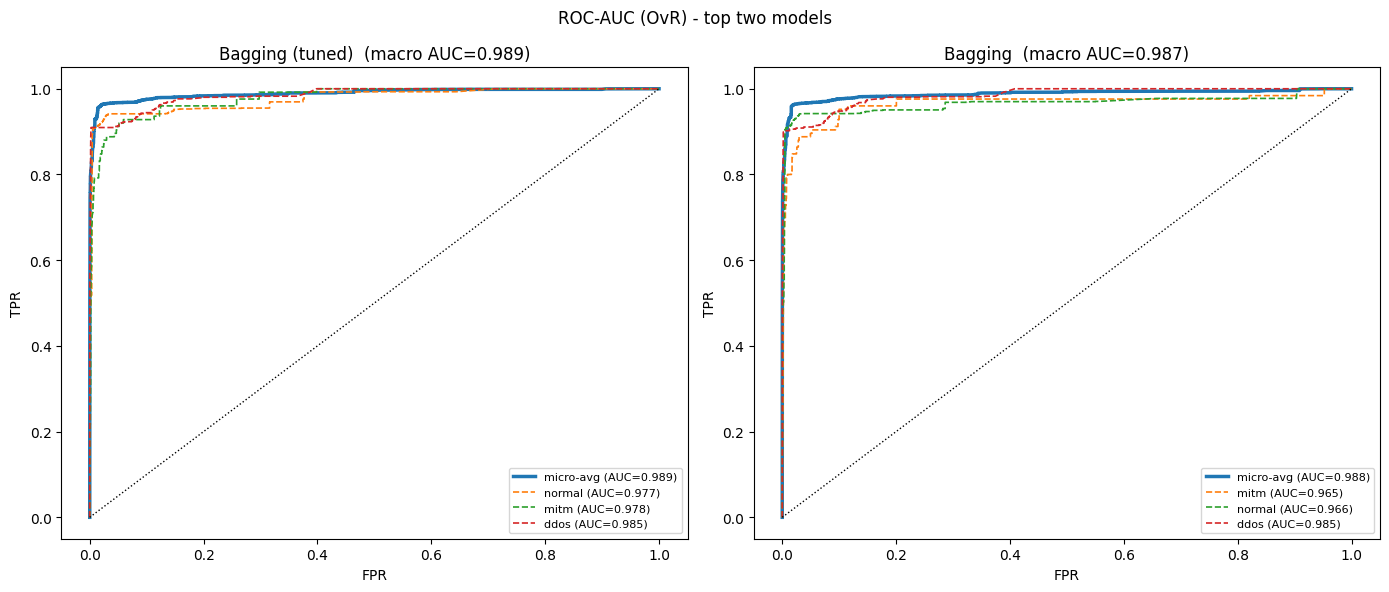

In [32]:
# --- ROC-AUC (OvR): top two models, test set ---
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
Y_bin = label_binarize(np.asarray(y_te, dtype=object), classes=LABELS)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, _name in zip(axes, top2_names):
    _proba = cmp_cache[_name].predict_proba(X_te)
    # one probability column per class in the test fold, in LABELS order
    _S = _proba[:, [list(cmp_cache[_name].classes_).index(_c) for _c in LABELS]]
    _fpr, _tpr, _auc = {}, {}, {}
    for _i, _c in enumerate(LABELS):
        _fpr[_c], _tpr[_c], _ = roc_curve(Y_bin[:, _i], _S[:, _i])
        _auc[_c] = auc(_fpr[_c], _tpr[_c])
    _fpr['micro'], _tpr['micro'], _ = roc_curve(Y_bin.ravel(), _S.ravel())
    _auc['micro'] = auc(_fpr['micro'], _tpr['micro'])
    _auc['macro'] = float(np.mean([_auc[_c] for _c in LABELS]))
    ax.plot(_fpr['micro'], _tpr['micro'], lw=2.5,
            label='micro-avg (AUC=%.3f)' % _auc['micro'])
    _worst = sorted(LABELS, key=lambda _c: _auc[_c])[:3]
    for _c in _worst:
        ax.plot(_fpr[_c], _tpr[_c], lw=1.2, ls='--',
                label='%s (AUC=%.3f)' % (_c, _auc[_c]))
    ax.plot([0, 1], [0, 1], 'k:', lw=1)
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.set_title(_name + '  (macro AUC=%.3f)' % _auc['macro'])
    ax.legend(fontsize=8, loc='lower right')
fig.suptitle('ROC-AUC (OvR) - top two models')
os.makedirs(os.path.join(ROOT, 'results/figures/toniot_partB'), exist_ok=True)
fig.tight_layout()
fig.savefig(os.path.join(ROOT, 'results/figures/toniot_partB/cls_roc_top2.png'), dpi=150, bbox_inches='tight')
print('Saved: results/figures/toniot_partB/cls_roc_top2.png')
plt.show()


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


C:\Users\chand\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but BaggingClassifier was fitted with feature names
  warnings.warn(


Saved: results/figures/toniot_partB/cls_cm_top2.png


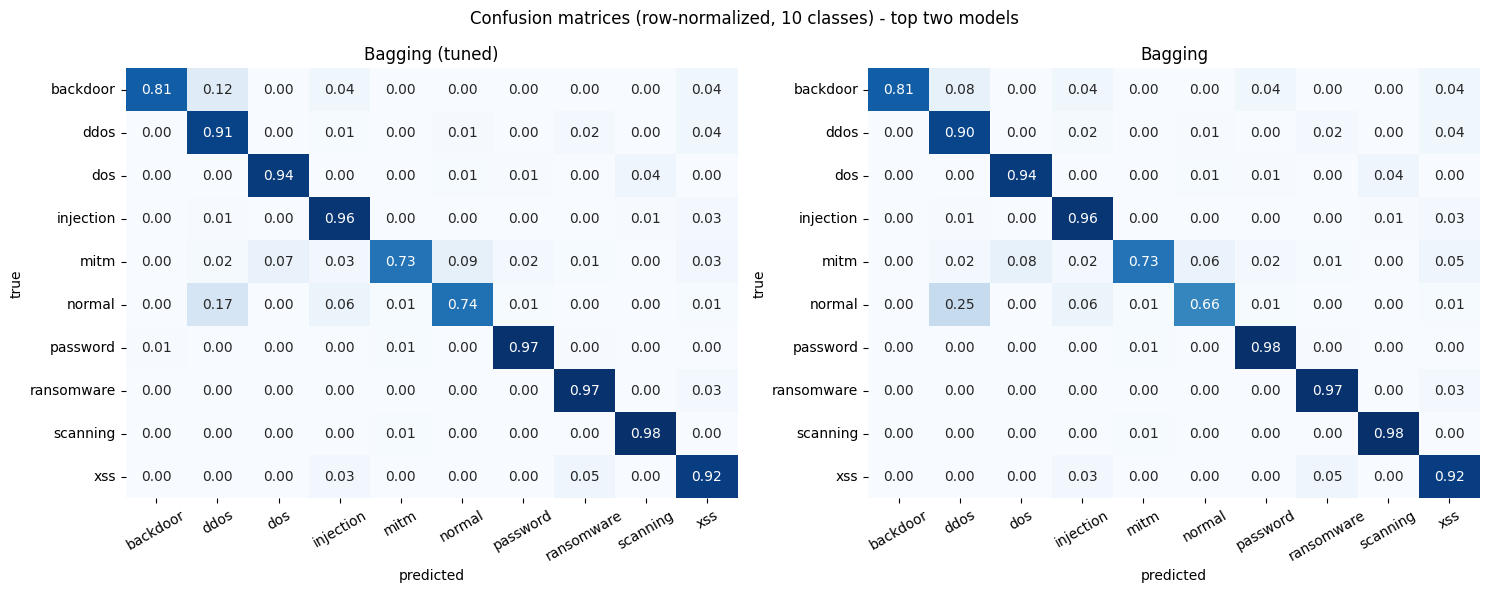

In [33]:
# --- Confusion matrices (row-normalized, all 10 classes, test set) ---
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, _name in zip(axes, top2_names):
    _cm = confusion_matrix(y_te, cmp_cache[_name].predict(X_te), labels=LABELS)
    _rs = _cm.sum(axis=1, keepdims=True)
    _cmn = np.divide(_cm, _rs, out=np.zeros_like(_cm, dtype=float), where=_rs != 0)
    sns.heatmap(_cmn, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(_name); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Confusion matrices (row-normalized, 10 classes) - top two models')
fig.tight_layout()
fig.savefig(os.path.join(ROOT, 'results/figures/toniot_partB/cls_cm_top2.png'), dpi=150, bbox_inches='tight')
print('Saved: results/figures/toniot_partB/cls_cm_top2.png')
plt.show()


## Inference — why tuned Bagging came out on top

This run uses a 50k stratified sample (37,682 training rows / 12,318 test rows). The split is grouped by `src_ip`, so the test side is whole machines the training set never saw, and all 10 attack types appear on both sides. Two things changed relative to the earlier version of this notebook: backdoor training support went from 39 rows to 4,884 (the old split had stranded it on the test side), and `dst_ip` was dropped in favour of an internal-destination flag, so no model can memorise host addresses anymore.

**Tuned Bagging (test F1w 0.925, macro 0.835, AUC 0.989) wins because it tops the weighted ranking and stays competitive on macro.** The lean tuning pass (8 configs, grouped inner CV on training only) moved it from 0.913 to 0.925 with 200 trees and `max_features` 0.3 — only the tree count and the per-split feature budget changed, nothing structural. Its per-class F1 on the test set: password 0.980, scanning 0.974, ransomware 0.974, injection 0.959, dos 0.937, normal 0.841, ddos 0.780, mitm 0.672, backdoor 0.667, xss 0.568. Nine of ten classes sit above 0.65; the misses are concentrated in the two smallest test slices (backdoor 26 rows, xss 133). Bagging's edge is the same as before: each tree sees a bootstrap resample and only 30% of the features at each split, so a split that only makes sense for one specific host can't dominate the vote. On a machine-held-out split that is the whole game, and the grouped-vs-stratified CV gap below confirms it.

**Gradient Boosting (base 0.887, tuned 0.885, AUC up to 0.992 — best ranking in the table) still loses on decisions.** Tuning helped its ranking and hurt its F1 slightly: the 100-tree, lr 0.05–0.1 configs rank classes beautifully and then misplace the boundary at argmax. Boosting keeps reweighting whatever the previous round got wrong, and on unseen machines the hard rows are hard because of host quirks, so later trees spend capacity chasing those instead of class structure. Same story as the last run, just at higher scores now that backdoor is trainable.

**The CV block reads the same way, only louder.** Stratified 5-fold (machines shared across folds): both top models at ~0.982, dead flat across folds. Grouped 5-fold by `src_ip`: ~0.52 mean with folds from 0.17 to 0.99. Same rows, same models — the only difference is whether a machine can appear on both sides. The test scores (~0.89–0.92) sit between those extremes, which is where a single held-out machine group should land. Anyone quoting the 0.98 number is measuring machine recognition; the grouped number is the deployment estimate.


### Why the rest are not better

- **Soft vote blend (F1w 0.889, macro 0.841 — best macro in the table, AUC 0.991).** Averaging the top-3 probabilities beats every base model except Bagging and actually leads on macro F1. It still trails tuned Bagging by 0.036 weighted because the blend inherits the members' shared blind spots (xss, backdoor) — averaging can't invent a signal none of the three has. Useful as a safety net, not as the headline.
- **Decision Tree (0.885, macro 0.780).** One unpruned tree with balanced weights. It nearly matches the ensembles on weighted F1 now that class weights stop it ignoring small classes, but a single tree's splits are all-or-nothing — where Bagging smooths host quirks by voting, this applies every host-specific split it learned to machines it never saw. AUC 0.917, lowest of the tree models, shows the ranking is brittle even where the decisions look fine.
- **Random Forest (0.883, macro 0.803).** 200 trees, balanced subsample weights, yet still 0.04 behind Bagging on weighted F1. Both are tree votes; the difference is the per-split feature budget (sqrt vs 30%) and the bootstrap scheme. On this data the wider feature draw wins — RF's trees agree with each other more, which helps on seen machines and hurts on new ones.
- **KNN (0.883, macro 0.806).** Distance voting doesn't care about class size, so it holds up on small classes without any weighting. It caps out here because Euclidean distance over 85 mixed-scale features is a blunt instrument — fine for separating normal from attack traffic, muddy between attack types with overlapping flow statistics.
- **Neural Network (0.881, macro 0.764).** A (100, 50) MLP with no class-weighting knob. AUC 0.965 says the ranking is solid; unweighted cross-entropy just drags the argmax thresholds toward the big classes, and the macro score pays for it. Tuning its width/alpha barely moved it — the loss function is the ceiling, not the architecture.
- **Tuned thresholds (0.874, macro 0.713).** Per-class thresholds picked on a grouped validation fold, and it *lost* 0.01 vs the argmax it started from. The validation fold's best thresholds don't transfer to the test machines — another face of the same host-shift problem. Honest negative result, kept in the table as such.
- **Two-stage detector (0.869, macro 0.783).** Binary gate then subtype model sounds right, but stage 1 errors are unrecoverable: anything the gate calls normal never reaches the subtype classifier. End-to-end it lands below every model it is built from. The binary gate itself scores well; the composition doesn't.
- **AdaBoost (0.854, macro 0.749).** Same reweighting idea as gradient boosting at learning_rate 1.0 with depth-3 trees and no shrinkage. Each round yanks hard toward the previous round's misses, which on unseen hosts are host artefacts — it overfits the training machines faster than GB does.
- **SVC-RBF (0.802).** Trains on the 12k subsample (quadratic cost) and every support vector comes from a seen host. Far from any training point the kernel responses collapse and the decision falls back toward the majority. Balanced weights keep it honest, but the geometry doesn't travel.
- **Logistic Regression (0.775, macro 0.615).** One hyperplane per class against attacks defined by feature interactions (bytes per packet, duration vs missed bytes). Flat boundaries, curved problem — and the macro score shows the small classes get none of the boundary budget.
- **Gaussian NB (0.324, macro 0.293).** Collapsed outright. Two things changed under it: the one-hot features it used to lean on are now string-typed and properly expanded (more sparse columns), and `dst_ip` removal took away the host-identity shortcut it was silently using. What remains exposes the model honestly — correlated flow counters counted several times over as if independent, log-counts treated as Gaussian, binary flags never Gaussian to begin with. It predicts normal for most of the test set and the weighted F1 follows it down.

### Two caveats before quoting these numbers

Backdoor has 26 test rows and xss 133, each from a single machine, so those two F1s (0.667, 0.568) will swing with any re-split — and because the classes are tiny, fixing or breaking them barely moves the weighted headline. Second, the grouped CV spread (folds 0.17–0.99) says the choice of *which* machines are held out matters more than the choice of model among the top five. The ranking Bagging > GB > tree > RF > KNN is real on this split, but the gaps between them are smaller than the gap between an easy machine group and a hard one.
